In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import roc_curve, auc,  roc_auc_score
from scipy.stats import randint,uniform

df=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv',index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')
df.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,4,1,2,0,2,0,0,0,0,0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,7,3,2,1,0,5,1,1,0,0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,7,3,1,1,0,5,1,0,0,0
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,4,1,1,1,2,1,1,0,0,0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,1,4,0,1,0,1,0,0,0,0


## 🛑 **Process to obtain the best model**

## 🛑 Task 1.1. PCA:  **Prediction of Death**

---



### 🛑FEATURE SELECTION

1. Improves Model Accuracy: By removing irrelevant features, the model can focus on the most important data points, leading to better performance.

2. Reduces Overfitting: Too many features can prevent your model from learning noise in the data. Reducing the feature set can help mitigate overfitting.
Speeds up Training: Less data means faster computation. Feature selection can significantly reduce the training time, especially with large datasets.

3. Enhances Interpretability: With fewer features, it’s easier to understand how the model makes decisions

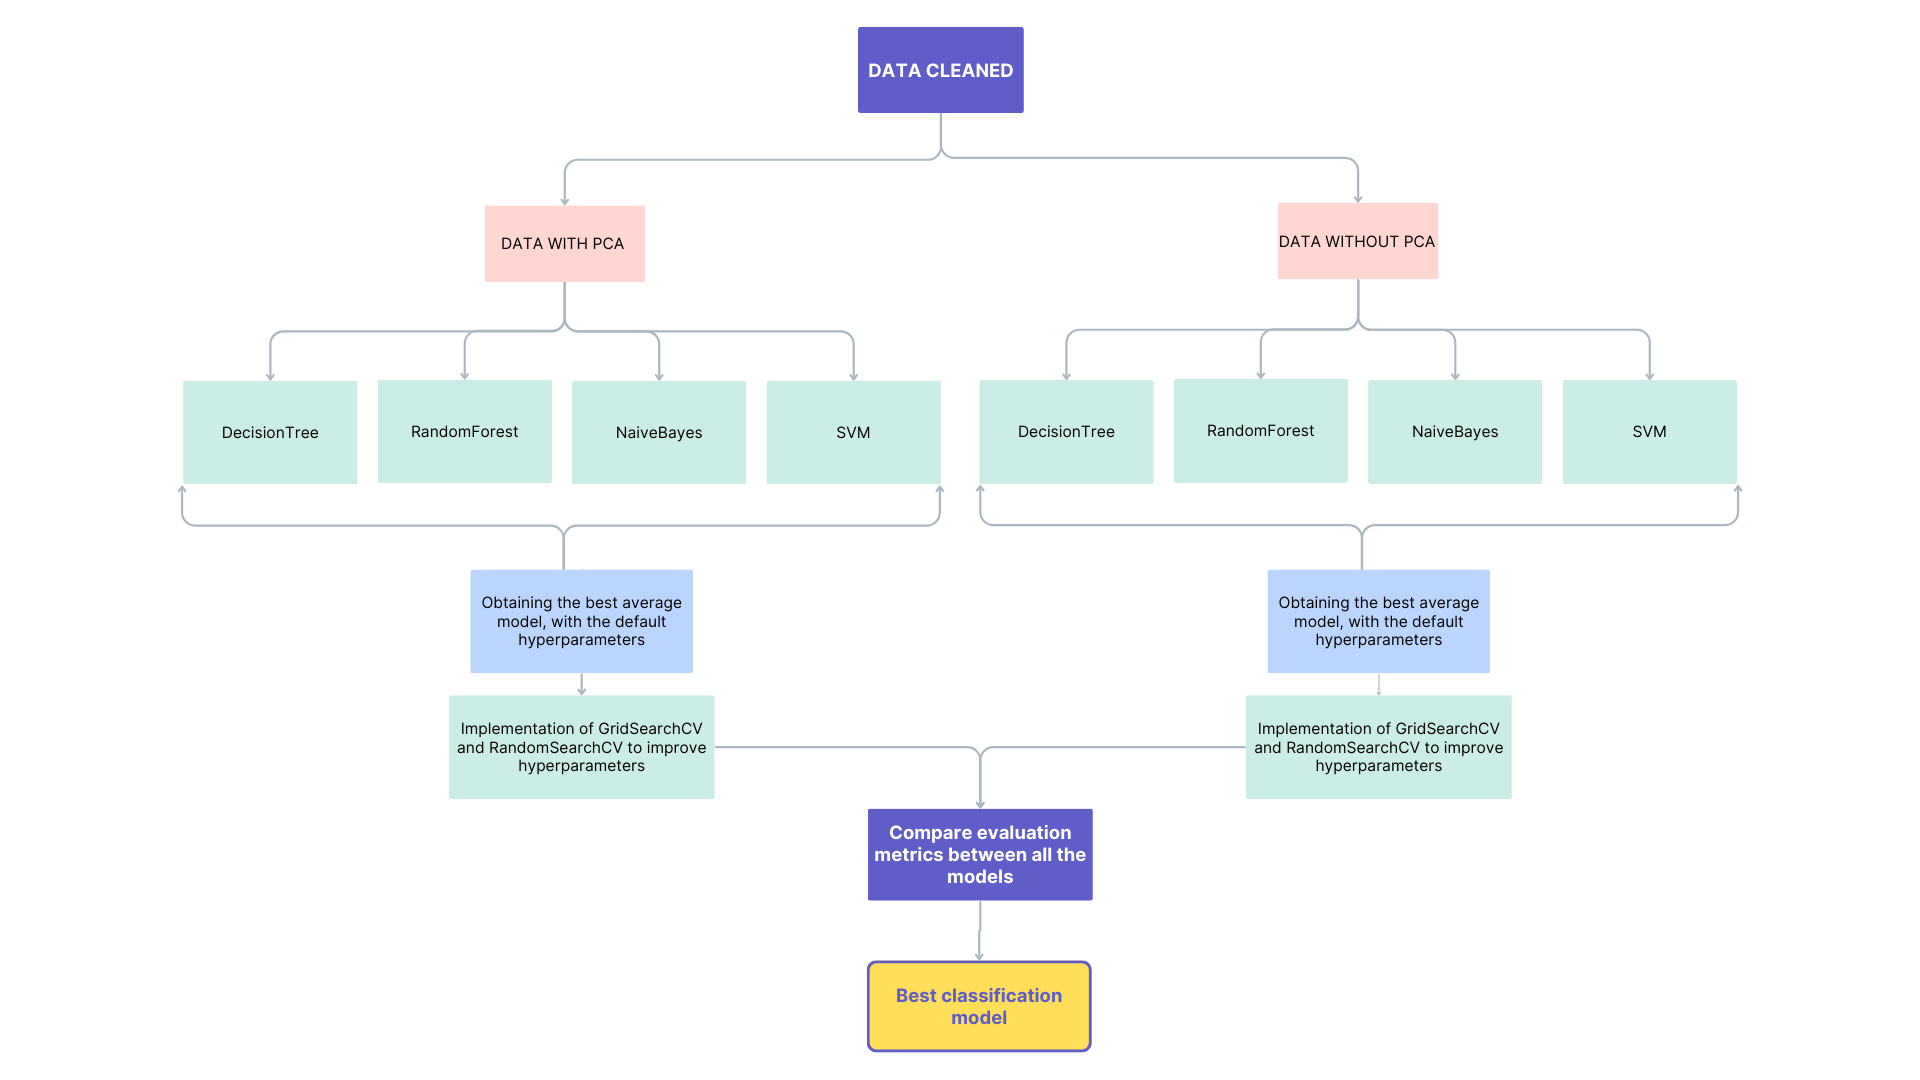

### 🛑 DATA SPLICING WE WILL USE STRATIFIED KFOLD

- First, we separate the data into the target variable and the features. It is crucial to identify and save the names of the qualitative columns, since principal component analysis (PCA) cannot be applied to them.

In [2]:
target=df['death']
features=df.drop(['death','hospdead'],axis=1)
categorical_features_cols= categorical_features.drop(['death','hospdead'],axis=1).columns

- We are using a 70/10/20 data split strategy, but this time, we will apply a stratified k-fold approach. Specifically, we will calculate 10 folds: 5 external folds and 2 internal folds for validation. 
    
    The external folds will determine the training and testing splits, while the internal folds will further divide the training data into training and validation sets. This ensures a robust evaluation process by maintaining the data distribution and minimizing potential biases.


Cumulative explained variance for each number of components: [0.14023324 0.23220936 0.31459182 0.38386811 0.43544604 0.48538473
 0.53395609 0.57852276 0.62128965 0.66352824 0.70429617 0.74169968
 0.77899063 0.81437633 0.84869631 0.88169528 0.91169569 0.94046985
 0.96457664 0.98844475 0.99602055 1.        ]


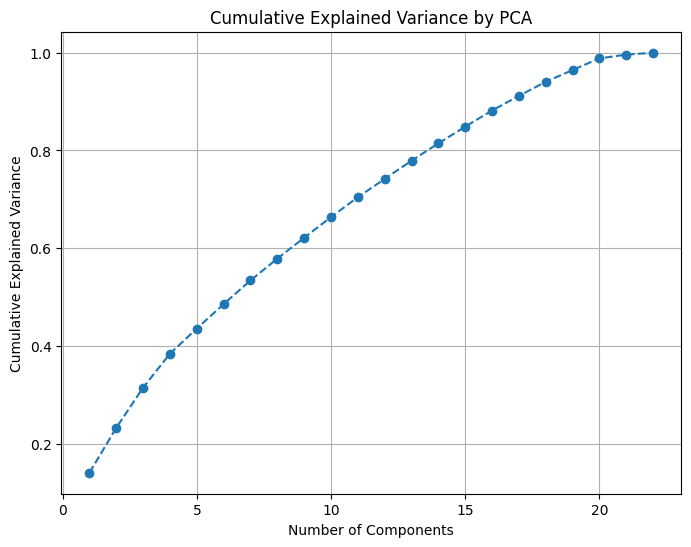

The optimal number of components to capture 85% of the variance is: 16


/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75730/54009021.py:112: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)


Cumulative explained variance for each number of components: [0.13472584 0.22610482 0.3078191  0.3770725  0.43065998 0.48345486
 0.53135795 0.57642901 0.62106837 0.66307447 0.70296604 0.74104635
 0.77783594 0.81366738 0.84705003 0.87882055 0.90887278 0.93748892
 0.96338164 0.98690151 0.99596904 1.        ]


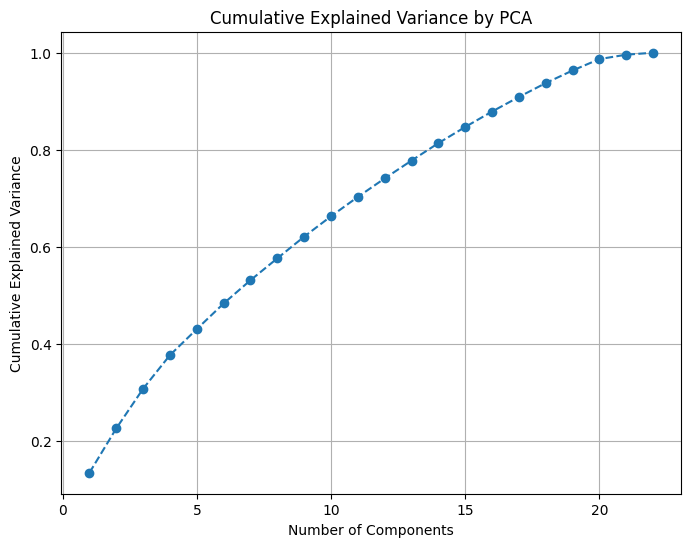

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.1397152  0.23170425 0.31134342 0.38028495 0.43365304 0.48507852
 0.53377495 0.57902644 0.6227502  0.66426421 0.70443118 0.74203214
 0.77897698 0.81438226 0.84755198 0.88032317 0.91000581 0.93834153
 0.96414674 0.98777563 0.99601393 1.        ]


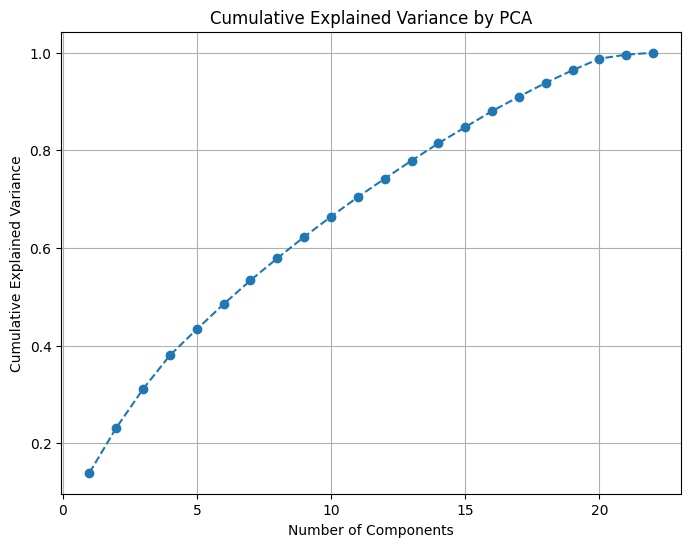

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13136924 0.22316033 0.30619274 0.37425885 0.42798852 0.47854683
 0.52724937 0.57221078 0.61645403 0.65861107 0.69891318 0.73632163
 0.7730655  0.80875479 0.84321915 0.87538742 0.90586509 0.93548828
 0.96067686 0.98434586 0.9959182  1.        ]


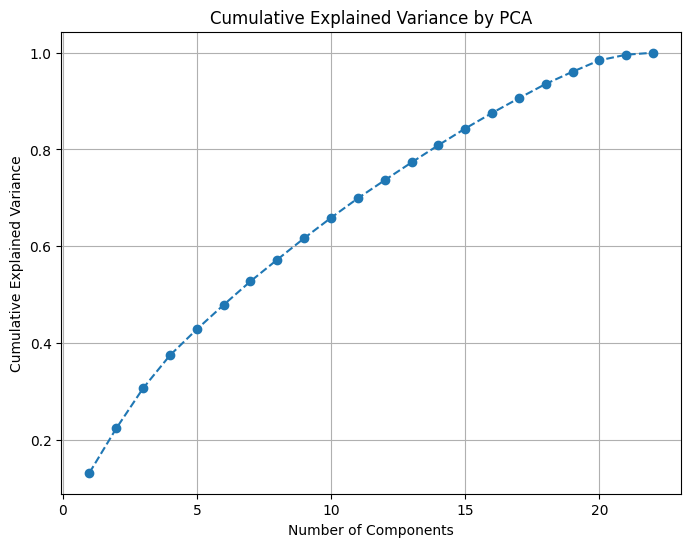

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13518771 0.22711782 0.31068323 0.38284697 0.43590426 0.48775516
 0.5350584  0.57931377 0.62325095 0.66575729 0.70589657 0.74394663
 0.78032679 0.81572816 0.84884462 0.88042508 0.90995139 0.93872141
 0.96438921 0.98842834 0.9963334  1.        ]


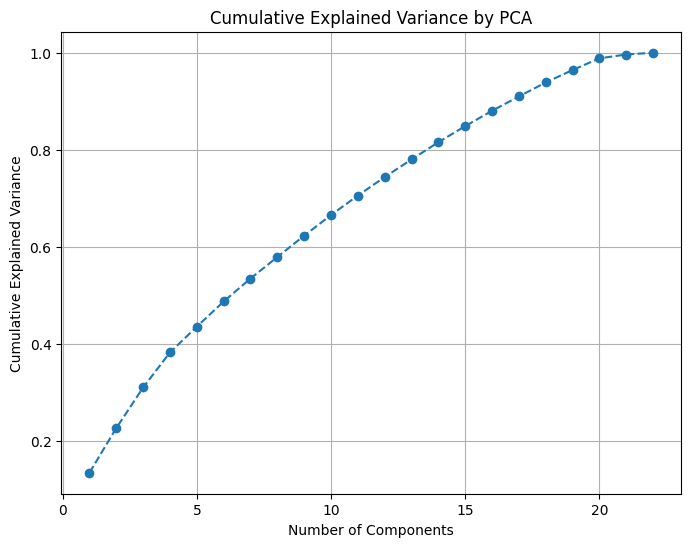

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13844296 0.2288046  0.31200104 0.37903299 0.43186817 0.48166152
 0.53070447 0.57613917 0.62002391 0.66249751 0.70279566 0.74157345
 0.77736507 0.81284027 0.84633059 0.87860658 0.9083505  0.93685368
 0.96131014 0.98480087 0.99566427 1.        ]


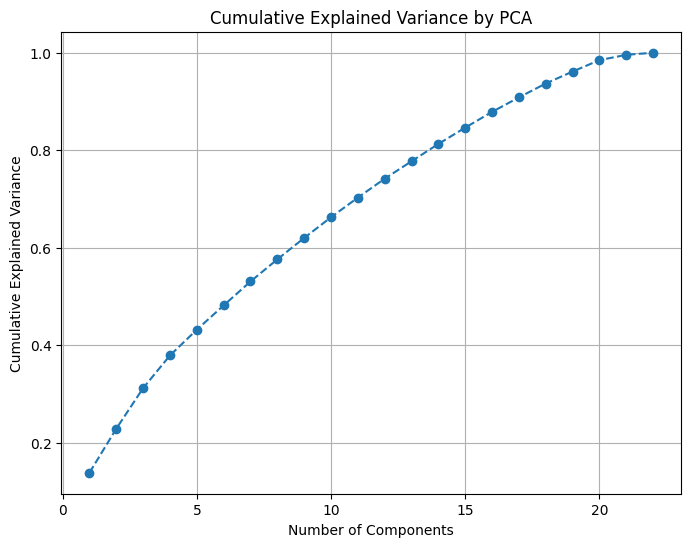

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13706969 0.22859259 0.30820487 0.37573849 0.43003643 0.48271686
 0.53088744 0.57603743 0.6195609  0.66205293 0.70331519 0.74193601
 0.77834754 0.81389005 0.84731024 0.87970235 0.90978629 0.93849056
 0.96318135 0.9871977  0.99613021 1.        ]


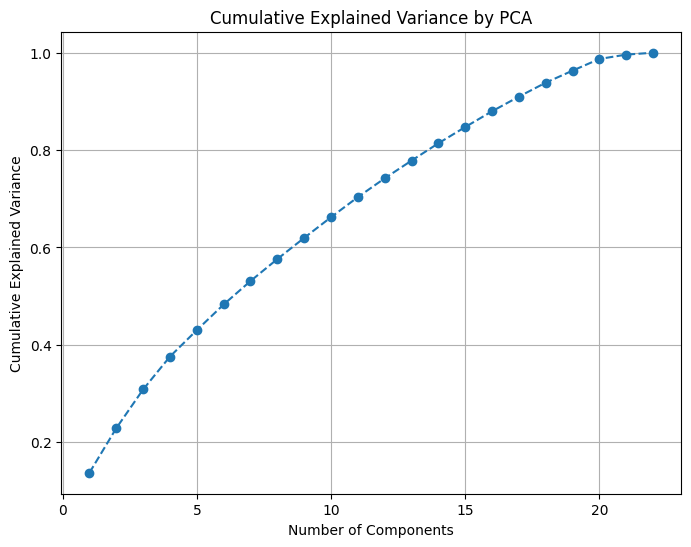

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13330059 0.22604651 0.30959785 0.3806413  0.43239481 0.48368561
 0.53180551 0.57654855 0.6188597  0.66080595 0.69997865 0.73822297
 0.77580012 0.81190863 0.8450919  0.87746063 0.90710668 0.93583593
 0.96223478 0.9864615  0.99613463 1.        ]


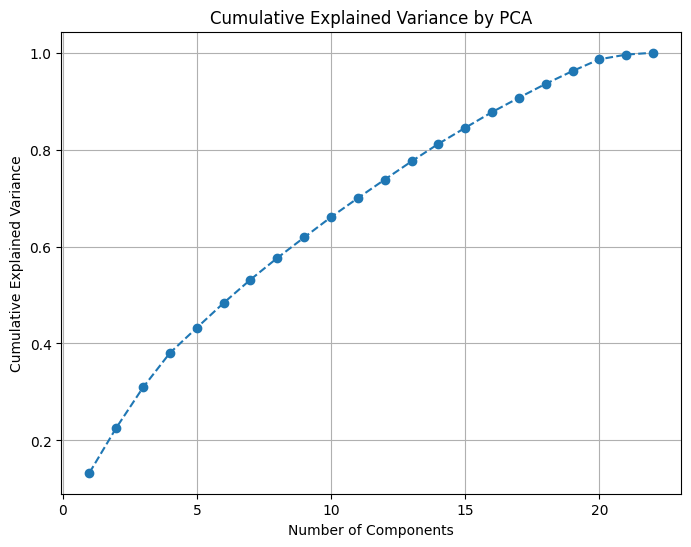

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13603416 0.22671334 0.31027196 0.37803196 0.43050093 0.48222077
 0.52893687 0.57369653 0.61728135 0.66006739 0.70076812 0.73891048
 0.77620281 0.8106351  0.84403103 0.87658291 0.90818389 0.93736273
 0.96262283 0.98649873 0.99597883 1.        ]


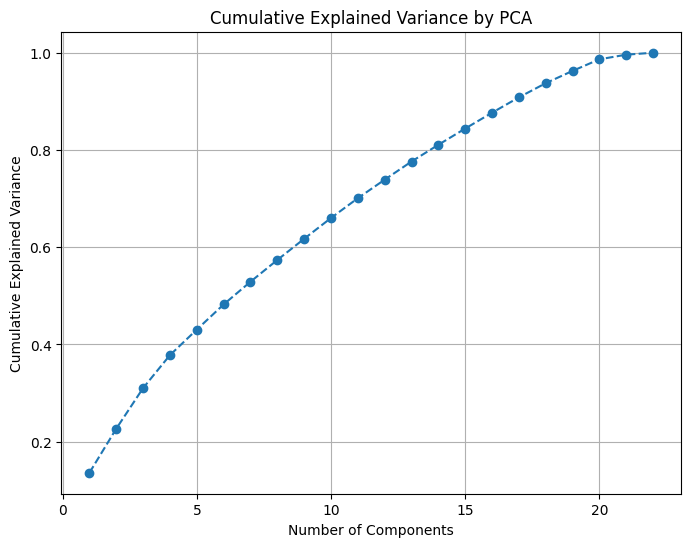

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13897956 0.22961603 0.30916955 0.3797886  0.43337798 0.48459371
 0.53436365 0.58055817 0.62415451 0.66571304 0.70544989 0.74340303
 0.78109018 0.81635996 0.84896497 0.88068759 0.91009434 0.93770883
 0.96230242 0.98641893 0.9959224  1.        ]


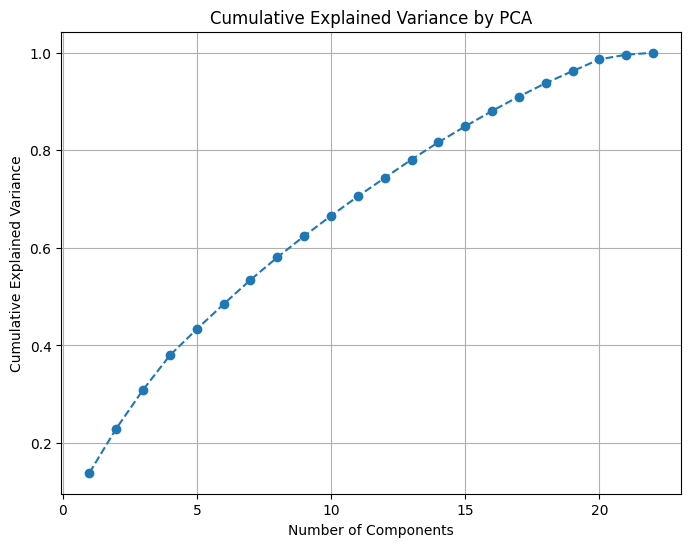

The optimal number of components to capture 85% of the variance is: 16
            Model  Accuracy  Precision    Recall  F1 Score       AUC
0   Decision Tree  0.727015   0.807167  0.787677  0.797303  0.692412
1   Random Forest  0.782066   0.837883  0.843464  0.840664  0.747044
2     Naïve Bayes  0.757094   0.882295  0.742714  0.806510  0.765297
3             SVM  0.776958   0.830065  0.845962  0.837938  0.737598
4   Decision Tree  0.738933   0.812131  0.802664  0.807370  0.702580
5   Random Forest  0.785471   0.832660  0.857619  0.844955  0.744317
6     Naïve Bayes  0.757662   0.880157  0.746045  0.807571  0.764288
7             SVM  0.786039   0.831190  0.860949  0.845808  0.743309
8   Decision Tree  0.727582   0.793496  0.811980  0.802632  0.679204
9   Random Forest  0.789444   0.845962  0.845258  0.845610  0.757450
10    Naïve Bayes  0.756527   0.878550  0.746256  0.807018  0.762414
11            SVM  0.796822   0.854027  0.846922  0.850459  0.768104
12  Decision Tree  0.741771   0.

In [3]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_pca = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])
# Diccionario para almacenar los DataFrames procesados
pca_data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        scaler = StandardScaler()
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_test = scaler.transform(X_test_quantitative)

        # Aplicar PCA
        pca = PCA()
        pca.fit(X_scaled_train)

        # Obtener y mostrar la varianza acumulada
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = explained_variance.cumsum()
        print(f"Cumulative explained variance for each number of components: {cumulative_variance}")

        # Graficar la varianza acumulada
        plt.figure(figsize=(8, 6))
        plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
        plt.title('Cumulative Explained Variance by PCA')
        plt.xlabel('Number of Components')
        plt.ylabel('Cumulative Explained Variance')
        plt.grid(True)
        plt.show()

        # Determinar el número óptimo de componentes
        optimal_components = next(i for i, value in enumerate(cumulative_variance) if value >= 0.85) + 1
        print(f"The optimal number of components to capture 85% of the variance is: {optimal_components}")

        # Aplicar PCA con el número óptimo de componentes
        pca_optimal = PCA(n_components=optimal_components)
        X_pca_optimal_train = pca_optimal.fit_transform(X_scaled_train)
        X_pca_optimal_val = pca_optimal.transform(X_scaled_val)
        X_pca_optimal_test = pca_optimal.transform(X_scaled_test)

        # Crear DataFrames para las componentes principales
        original_X_train_index = X_train.index
        original_X_val_index = X_val.index
        original_X_test_index = X_test.index

        pca_X_train = pd.DataFrame(X_pca_optimal_train, index=original_X_train_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_train = pd.concat([pca_X_train, X_train_qualitative], axis=1)

        pca_X_val = pd.DataFrame(X_pca_optimal_val, index=original_X_val_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_val = pd.concat([pca_X_val, X_val_qualitative], axis=1)

        pca_X_test = pd.DataFrame(X_pca_optimal_test, index=original_X_test_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_test = pd.concat([pca_X_test, X_test_qualitative], axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': pca_X_train,
            'Train_Y': y_train,
            'Validation_X': pca_X_val,
            'Validation_Y': y_val,
            'Test_X': pca_X_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        pca_data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(pca_X_train, y_train)
        y_pred_dt = model_dt.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt),
            'Recall': recall_score(y_test, y_pred_dt),
            'F1 Score': f1_score(y_test, y_pred_dt),
            'AUC': roc_auc_score(y_test, y_pred_dt)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(pca_X_train, y_train)
        y_pred_rf = model_rf.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf),
            'Recall': recall_score(y_test, y_pred_rf),
            'F1 Score': f1_score(y_test, y_pred_rf),
            'AUC': roc_auc_score(y_test, y_pred_rf)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(pca_X_train, y_train)
        y_pred_nb = model_nb.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb),
            'Recall': recall_score(y_test, y_pred_nb),
            'F1 Score': f1_score(y_test, y_pred_nb),
            'AUC': roc_auc_score(y_test, y_pred_nb)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(pca_X_train, y_train)
        y_pred_svm = model_svm.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm),
            'Recall': recall_score(y_test, y_pred_svm),
            'F1 Score': f1_score(y_test, y_pred_svm),
            'AUC': roc_auc_score(y_test, y_pred_svm)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_pca)



#### 🛑 Results for predefinded Models

In [4]:
# Promedios por modelo
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.734987,0.807533,0.802927,0.805158,0.696089
Naïve Bayes,0.759111,0.881141,0.747670,0.808924,0.765659
Random Forest,0.785731,0.837784,0.850616,0.844091,0.748586
SVM,0.788683,0.840789,0.851697,0.846110,0.752612


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model 1.1. PCA
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **SVM** model. This model demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

### SVM 1.1 PCA Hyperparameter Turning

````
# Inicialización de DataFrames
df_hyperparameters_gridsearch = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch = pd.concat([df_hyperparameters_gridsearch, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch = pd.concat([df_hyperparameters_randomsearch, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch)
df_hyperparameters_gridsearch.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/GRIDSEARCH_PCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch)
df_hyperparameters_randomsearch.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/RANDOMSEARCH_PCA_SVM.csv')

In [5]:
print('GridSearchCV')
df_hyperparameters_gridsearch = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/GRIDSEARCH_PCA_SVM.csv')
df_hyperparameters_gridsearch[df_hyperparameters_gridsearch['Accuracy'] == df_hyperparameters_gridsearch['Accuracy'].max()]


GridSearchCV


,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
4,4,Fold_Externo_2-Fold_Interno_1,1,poly,3,scale,0.794829


In [6]:
# Mostrar resultados
print("Random Search")
df_hyperparameters_randomsearch = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/RANDOMSEARCH_PCA_SVM.csv')
df_hyperparameters_randomsearch[df_hyperparameters_randomsearch['Accuracy'] == df_hyperparameters_randomsearch['Accuracy'].max()]


Random Search


,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
5,5,Fold_Externo_2-Fold_Interno_2,0.787921,rbf,5,auto,0.785686


### 🟢 Evaluation of SVM for Death Prediction with PCA (Hyperparameter Tuning)


- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH SVM**

In [7]:
SVM_df_hyperparameter_turning = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'poly')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS)
        recall_GS = recall_score(data['Test_Y'], y_pred_GS)
        f1_GS = f1_score(data['Test_Y'], y_pred_GS)
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS],
            'AUC': [auc_score_GS]
        })
        SVM_df_hyperparameter_turning=pd.concat([SVM_df_hyperparameter_turning,new_row], ignore_index=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75730/1924617241.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  SVM_df_hyperparameter_turning=pd.concat([SVM_df_hyperparameter_turning,new_row], ignore_index=True)


- USE OF PARAMETERS GIVEN BY THE **RANDOM SEARCH SVM**

In [8]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=0.787921	,
            degree=5,
            gamma='scale',
            kernel='rbf'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='binary')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='binary')                
        auc_score_RS = roc_auc_score(data['Test_Y'], y_pred_RS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
            'AUC': auc_score_RS
        }])

        # Concatenar los resultados
        SVM_df_hyperparameter_turning = pd.concat([SVM_df_hyperparameter_turning, new_row], ignore_index=True)


SVM_df_hyperparameter_turning.groupby('Model').mean()


,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Super Vector Machine GS,0.789591,0.844897,0.847121,0.845930,0.756661
Support Vector Machine RS,0.788399,0.839903,0.852446,0.846033,0.751735


## 🛑 Task 1.1. WITHOUT PCA:  **Prediction of Death**

---



### 🛑FEATURE SELECTION

1. Improves Model Accuracy: By removing irrelevant features, the model can focus on the most important data points, leading to better performance.

2. Reduces Overfitting: Too many features can prevent your model from learning noise in the data. Reducing the feature set can help mitigate overfitting.
Speeds up Training: Less data means faster computation. Feature selection can significantly reduce the training time, especially with large datasets.

3. Enhances Interpretability: With fewer features, it’s easier to understand how the model makes decisions

### 🛑 DATA SPLICING

- First, we separate the data into the target variable and the features.

In [9]:
target=df['death']
features=df.drop(['death','hospdead'],axis=1)
categorical_features_cols= categorical_features.drop(['death','hospdead'],axis=1).columns

In [10]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_scaled= pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])
# Diccionario para almacenar los DataFrames procesados
data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(X_scaled_train, y_train)
        y_pred_dt = model_dt.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt),
            'Recall': recall_score(y_test, y_pred_dt),
            'F1 Score': f1_score(y_test, y_pred_dt),
            'AUC': roc_auc_score(y_test, y_pred_dt)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(X_scaled_train, y_train)
        y_pred_rf = model_rf.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf),
            'Recall': recall_score(y_test, y_pred_rf),
            'F1 Score': f1_score(y_test, y_pred_rf),
            'AUC': roc_auc_score(y_test, y_pred_rf)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(X_scaled_train, y_train)
        y_pred_nb = model_nb.predict(X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb),
            'Recall': recall_score(y_test, y_pred_nb),
            'F1 Score': f1_score(y_test, y_pred_nb),
            'AUC': roc_auc_score(y_test, y_pred_nb)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(X_scaled_train, y_train)
        y_pred_svm = model_svm.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm),
            'Recall': recall_score(y_test, y_pred_svm),
            'F1 Score': f1_score(y_test, y_pred_svm),
            'AUC': roc_auc_score(y_test, y_pred_svm)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_scaled)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75730/3099592200.py:84: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)


            Model  Accuracy  Precision    Recall  F1 Score       AUC
0   Decision Tree  0.730420   0.804020  0.799334  0.801670  0.691111
1   Random Forest  0.783201   0.838150  0.845129  0.841625  0.747876
2     Naïve Bayes  0.766742   0.888780  0.751873  0.814614  0.775224
3             SVM  0.786606   0.834550  0.856786  0.845522  0.746575
4   Decision Tree  0.742906   0.815346  0.805162  0.810222  0.707394
5   Random Forest  0.800795   0.845528  0.865945  0.855615  0.763632
6     Naïve Bayes  0.766742   0.885742  0.755204  0.815281  0.773324
7             SVM  0.792849   0.836554  0.865112  0.850594  0.751629
8   Decision Tree  0.759932   0.825397  0.821963  0.823677  0.724375
9   Random Forest  0.788876   0.839607  0.853577  0.846535  0.751789
10    Naïve Bayes  0.765040   0.886275  0.752080  0.813681  0.772469
11            SVM  0.788876   0.851695  0.836106  0.843829  0.761803
12  Decision Tree  0.761635   0.814309  0.842762  0.828291  0.715131
13  Random Forest  0.793417   0.83

#### 🛑 Results for predefinded Models

In [11]:
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.744749,0.810132,0.817406,0.813697,0.703150
Naïve Bayes,0.761722,0.881091,0.752165,0.811526,0.767190
Random Forest,0.791124,0.837396,0.861018,0.848990,0.751106
SVM,0.792997,0.843391,0.855444,0.849307,0.757251


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model 1.1. NO PCA
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **Random Forest and SVM** models. These models demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.1 NO PCA Hyperparameter Turning

````

# Inicialización de DataFrames
df_hyperparameters_gridsearch_NoPCA = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_NoPCA = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_NoPCA_SVM  = pd.concat([df_hyperparameters_gridsearch_NoPCA_SVM , new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_NoPCA_SVM  = pd.concat([df_hyperparameters_randomsearch_NoPCA_SVM , new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_NoPCA_SVM)
df_hyperparameters_gridsearch_NoPCA_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/GRIDSEARCH_NOpca_SVM.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_NoPCA_SVM)
df_hyperparameters_randomsearch_NoPCA_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/RANDOMSEARCH_NOpca_SVM.csv')


In [12]:
df_hyperparameters_gridsearch_NoPCA_SVM = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/GRIDSEARCH_NoPCA_SVM.csv')
print(df_hyperparameters_gridsearch_NoPCA_SVM[df_hyperparameters_gridsearch_NoPCA_SVM['Accuracy'] == df_hyperparameters_gridsearch_NoPCA_SVM['Accuracy'].max()])

df_hyperparameters_randomsearch_NoPCA_SVM = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/RANDOMSEARCH_NoPCA_SVM.csv')
print(df_hyperparameters_randomsearch_NoPCA_SVM[df_hyperparameters_randomsearch_NoPCA_SVM['Accuracy'] == df_hyperparameters_randomsearch_NoPCA_SVM['Accuracy'].max()])

   Unnamed: 0                           Fold  C Kernel  Degree  Gamma  \
5           5  Fold_Externo_2-Fold_Interno_1  1   poly       3  scale   

   Accuracy  
5  0.799368  
   Unnamed: 0                           Fold          C  Kernel  Degree  \
3           3  Fold_Externo_1-Fold_Interno_1  44.785039  linear       3   

   Gamma  Accuracy  
3  scale  0.785185  




---

#### RandomForest 1.1 NO PCA Hyperparameter Turning


`````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_NoPCA_RF = pd.DataFrame(columns=['Fold', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])
df_hyperparameters_randomsearch_NoPCA_RF = pd.DataFrame(columns=['Fold', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])

# Modelo base
model_rf = RandomForestClassifier(random_state=42)

# Espacio de hiperparámetros para GridSearchCV
param_grid_rf = {
    'n_estimators': [10, 20],  # Número de árboles
    'max_depth': [None, 10, 20],  # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Número de características a considerar para dividir
    'bootstrap': [True, False],  # Usar bootstrap o no
}

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(10, 20),  # Número aleatorio de árboles
    'max_depth': [None] + list(range(10, 101, 10)),  # Profundidad aleatoria
    'min_samples_split': randint(2, 20),  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': randint(1, 10),  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Características a considerar
    'bootstrap': [True, False],  # Usar bootstrap o no
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_rf,
            param_grid=param_grid_rf,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'n_estimators': grid_search.best_params_['n_estimators'],
            'max_depth': grid_search.best_params_['max_depth'],
            'min_samples_split': grid_search.best_params_['min_samples_split'],
            'min_samples_leaf': grid_search.best_params_['min_samples_leaf'],
            'max_features': grid_search.best_params_['max_features'],
            'bootstrap': grid_search.best_params_['bootstrap'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_NoPCA_RF = pd.concat([df_hyperparameters_gridsearch_NoPCA_RF, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_rf,
            param_distributions=param_dist_rf,
            n_iter=10,
            scoring='accuracy',
            cv=5,
            random_state=42
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'n_estimators': random_search.best_params_['n_estimators'],
            'max_depth': random_search.best_params_['max_depth'],
            'min_samples_split': random_search.best_params_['min_samples_split'],
            'min_samples_leaf': random_search.best_params_['min_samples_leaf'],
            'max_features': random_search.best_params_['max_features'],
            'bootstrap': random_search.best_params_['bootstrap'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_NoPCA_RF = pd.concat([df_hyperparameters_randomsearch_NoPCA_RF, new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_NoPCA_RF)
df_hyperparameters_gridsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/GRIDSEARCH_NOpca_RF.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_NoPCA_RF)
df_hyperparameters_randomsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/RANDOMSEARCH_NOpca_RF.csv')


In [13]:
df_hyperparameters_gridsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/GRIDSEARCH_NoPCA_RF.csv')
print(df_hyperparameters_gridsearch_NoPCA_RF[df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'] == df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'].max()])

df_hyperparameters_randomsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.1_Model Analysis For Death/RANDOMSEARCH_NoPCA_RF.csv')
print(df_hyperparameters_randomsearch_NoPCA_RF[df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'] == df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'].max()])


   Unnamed: 0                           Fold  n_estimators  max_depth  \
4           4  Fold_Externo_2-Fold_Interno_1            20         10   

   min_samples_split  min_samples_leaf max_features  bootstrap  Accuracy  
4                 10                 4         sqrt      False   0.79767  
   Unnamed: 0                           Fold  n_estimators  max_depth  \
4           4  Fold_Externo_2-Fold_Interno_1            19         30   

   min_samples_split  min_samples_leaf max_features  bootstrap  Accuracy  
4                  8                 8         sqrt       True  0.794835  


### 🟢 Evaluation of SVM and Random Forest Models for Death Prediction with NoPCA (Hyperparameter Tuning)


- USE OF PARAMETERS GIVEN BY **GRIDSEARCH SVM**

In [14]:
df_hyperparameter_turning_NoPCA = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'poly')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS)
        recall_GS = recall_score(data['Test_Y'], y_pred_GS)
        f1_GS = f1_score(data['Test_Y'], y_pred_GS)
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS],
            'AUC': [auc_score_GS]
        })
        df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75730/1052767105.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)


- USE OF PARAMETERS GIVEN BY **RANDOMSEARCHCV SVM**

In [15]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=44.785039,
            degree=3,
            gamma='scale',
            kernel='linear'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='binary')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='binary')                
        auc_score_RS = roc_auc_score(data['Test_Y'], y_pred_RS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
            'AUC': auc_score_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)



- USE OF PARAMETERS GIVEN BY **GRIDSEARCH RF**

In [16]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            n_estimators=20,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features='sqrt',
            max_depth=10,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='binary')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_GS, average='binary')                
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS,
            'AUC': auc_score_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

- USE OF PARAMETERS GIVEN BY **RANDOMSEARCH RF**

In [17]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            n_estimators=19,
            min_samples_split=8,
            min_samples_leaf=8,
            max_features='sqrt',
            max_depth=30,
            bootstrap=True,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='binary')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='binary')                
        auc_score_RS = roc_auc_score(data['Test_Y'], y_pred_RS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
            'AUC': auc_score_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

df_hyperparameter_turning_NoPCA.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
RANDOM FOREST GS,0.783063,0.834613,0.850530,0.851608,0.744434
RANDOM FOREST RS,0.777614,0.826270,0.853443,0.839540,0.734202
Super Vector Machine GS,0.789591,0.844897,0.847121,0.845930,0.756661
Support Vector Machine RS,0.772507,0.852073,0.806593,0.828638,0.752994




---


# 🟢 Results Tasks 1.1

### **ANALYSIS: Models obtained with data trained using PCA**

In [18]:
# Promedios por modelo by default con PCA
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.734987,0.807533,0.802927,0.805158,0.696089
Naïve Bayes,0.759111,0.881141,0.747670,0.808924,0.765659
Random Forest,0.785731,0.837784,0.850616,0.844091,0.748586
SVM,0.788683,0.840789,0.851697,0.846110,0.752612


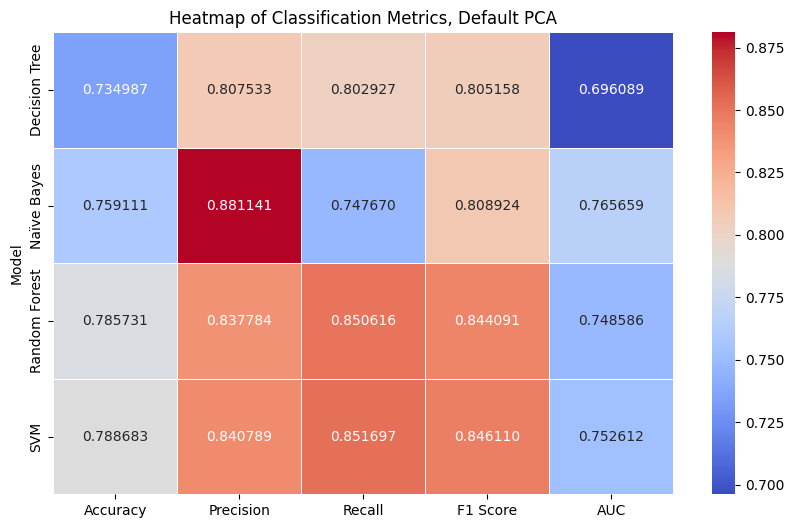

In [19]:
df_heatmap = evaluation_metrics_pca.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default PCA")
plt.show()

We have chosen to select the SVM and de random forest models because, while all the models evaluated show similar performance in terms of **accuracy**, the SVM and RF stands out for its higher **sensitivity**. Since our main objective is to classify a patient's disposition to a fatal outcome, we prefer a model that is able to minimize **false negatives**, even if this implies a higher number of **false positives**. This approach is crucial, since we prioritize correctly identifying patients at risk.

In [20]:
SVM_df_hyperparameter_turning.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Super Vector Machine GS,0.789591,0.844897,0.847121,0.845930,0.756661
Support Vector Machine RS,0.788399,0.839903,0.852446,0.846033,0.751735


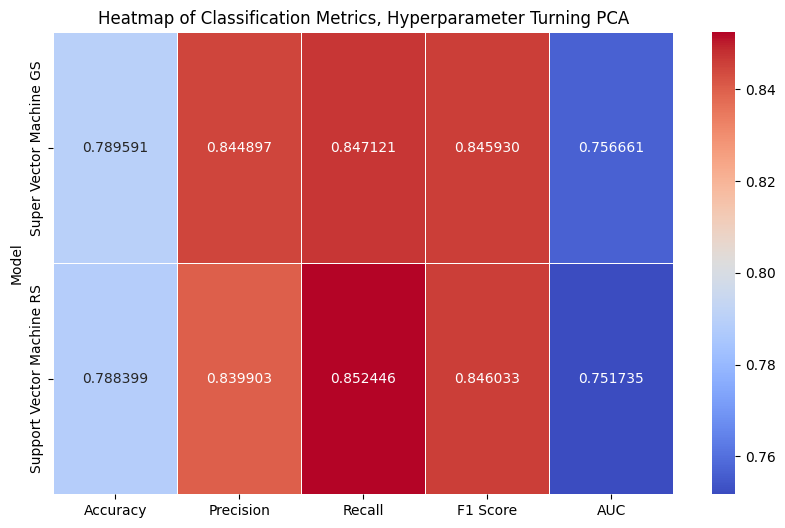

In [21]:
df_heatmap = SVM_df_hyperparameter_turning.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning PCA")
plt.show()

In this analysis, our main goal is to prioritize **Recall**, since we are classifying deaths and we are interested in minimizing false negatives, i.e., cases in which we do not correctly detect a death.

Of all the models evaluated, the **SVM with Random Search (SVM RS)** is the best option because it achieves the highest **Recall, with a value of 0.8524**. This means that it is the model that best identifies positive cases. In addition, it maintains solid performance in the other metrics, with a **Precision of 0.8399**, an **F1 Score of 0.8460**, an **Accuracy of 0.7884**, and an **AUC of 0.7517**. This indicates that the model, in addition to prioritizing sensitivity, maintains an adequate balance in other aspects.

On the other hand, the **SVM with Grid Search (SVM GS)** presents a slightly lower Recall of **0.8471**, but offers better results in **Precision (0.8449)**, **Accuracy (0.7896)** and especially in **AUC (0.7566)**, which means that it discriminates a little better between classes at different thresholds.

In conclusion, if **Recall is our priority**, the **SVM RS** is the most suitable model. However, if we are looking for a little additional balance in other metrics, such as AUC or accuracy, the **SVM GS** is also a valid alternative.

### **ANALYSIS: Models obtained with data trained without using PCA**

In [22]:
# Promedios por modelo by default sin PCA, valores escalados
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.744749,0.810132,0.817406,0.813697,0.703150
Naïve Bayes,0.761722,0.881091,0.752165,0.811526,0.767190
Random Forest,0.791124,0.837396,0.861018,0.848990,0.751106
SVM,0.792997,0.843391,0.855444,0.849307,0.757251


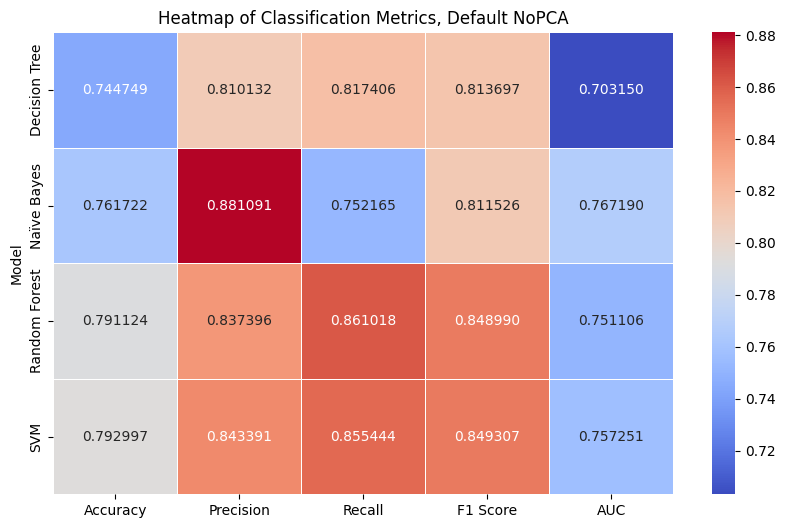

In [23]:
df_heatmap = evaluation_metrics_scaled.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default NoPCA")
plt.show()

We selected the SVM and Random Forest (RF) models due to their outstanding sensitivity (recall), a crucial factor in our context. While all the evaluated models show similar performance in terms of precision (around 79%), the heatmap reveals that both SVM and RF significantly outperform each other in recall (0.8554 and 0.8610, respectively). This value reflects their ability to correctly identify at-risk patients, which is essential for our main goal: minimizing false negatives.

In addition to their high sensitivity, both models also show a strong balance in other metrics such as the F1 Score (0.8493 for SVM and 0.8489 for RF), which confirms their overall performance capability. While models such as Naïve Bayes have high precision (0.8811), their low recall (0.7522) makes them less suitable for our application, where the cost of not detecting an at-risk patient is unacceptable.

Therefore, the combination of high recall and consistent performance on other metrics in both SVM and Random Forest models makes them the most favorable options, allowing us to prioritize the identification of at-risk patients, even if this implies a slight increase in false positives.

In [24]:
df_hyperparameter_turning_NoPCA.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
RANDOM FOREST GS,0.783063,0.834613,0.850530,0.851608,0.744434
RANDOM FOREST RS,0.777614,0.826270,0.853443,0.839540,0.734202
Super Vector Machine GS,0.789591,0.844897,0.847121,0.845930,0.756661
Support Vector Machine RS,0.772507,0.852073,0.806593,0.828638,0.752994


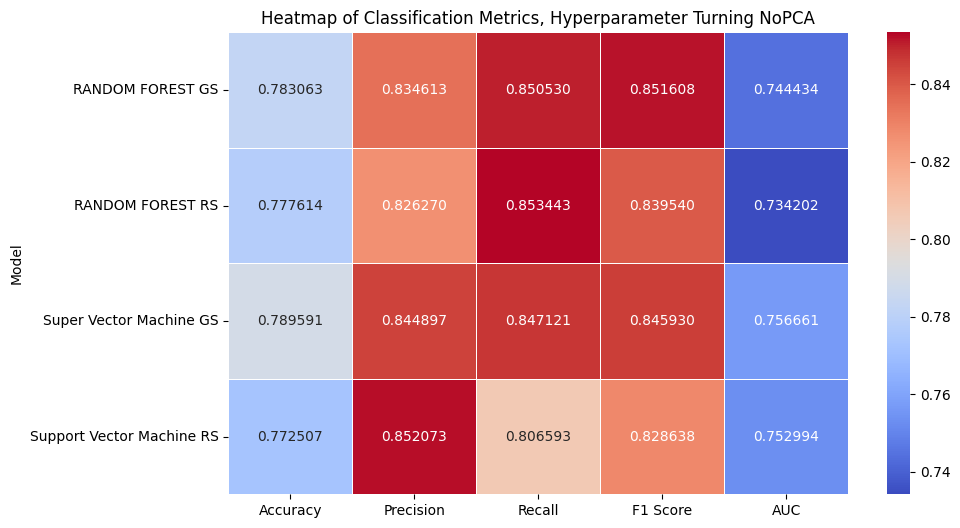

In [25]:
df_heatmap = df_hyperparameter_turning_NoPCA.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning NoPCA")
plt.show()

After analyzing the evaluated models, considering **Recall** as the most important metric and without ignoring the rest (Accuracy, Precision, F1 Score and AUC), I conclude that **Random Forest with default parameters** and **SVM GS** tuned are the most competitive models.

The **Default Random Forest** stands out for having the **highest Recall** (0.861), which makes it ideal if you want to minimize false negatives. In addition, its **F1 Score** (0.8489) and **Precision** (0.8373) are solid, although its **AUC** (0.7511) could be better.

On the other hand, the **SVM GS** presents a better overall balance between metrics: it has a notable Recall (0.8471), a high Precision (0.8448), and achieves the **highest AUC** (0.7566), which indicates a better performance in terms of overall classification.

Therefore, the **best final model** is **SVM GS**, as it offers a more balanced and consistent performance across all key metrics.

### **ANALYSIS: Better PCA Model vs No PCA Model**

After analyzing both **SVM GS** models with and without PCA, I conclude that in terms of metrics they are **equivalent**, as they show identical values ​​in **Precision, Recall, F1 Score, Accuracy, and AUC**. However, the key difference lies in computational performance.

The **SVM GS with PCA** model reduces dimensionality, making it more efficient in terms of time and resources, without sacrificing performance quality. By reducing the number of variables, the processing of the model is facilitated, which is essential in applications where time and resources are limited.

Therefore, the **best model** is **SVM GS with PCA**, as it achieves the same performance as its version without PCA, but with optimized computational performance. This advantage makes it the most efficient and practical option.